<figure>
<center>
<img src='https://www.economicas.uba.ar/wp-content/uploads/2020/08/cropped-logo_FCE.png' />
</figure>

#<center>Pandas</center>

### **¿Qué es Pandas?**

**Pandas** es la librería más importante de Python para el análisis de datos. Permite trabajar con datos tabulares (como una planilla de Excel o una tabla de base de datos) de forma eficiente y expresiva.

Sus dos estructuras principales son:

| Estructura | Descripción | Analogía |
|---|---|---|
| **Series** | Columna de datos con índice | Una columna de Excel |
| **DataFrame** | Tabla de datos (filas y columnas) | Una hoja de Excel completa |

Pandas está construido sobre NumPy, por lo que las operaciones son eficientes y vectorizadas.

En esta notebook veremos:
- Series y DataFrames
- Exploración de datos
- Acceso a filas y columnas
- Filtrado
- Agregar y modificar columnas
- Valores faltantes
- Ordenamiento
- Agregación con `groupby()`
- Visualización integrada

---
### **Importar Pandas**

In [ ]:
import pandas as pd
import numpy as np

NameError: name 'sns' is not defined

---
### **Series**

Una **Series** es una secuencia de valores con un **índice** asociado. Es como una lista de Python, pero con etiquetas para cada elemento.

```python
serie = pd.Series(datos, index=etiquetas)
```

In [ ]:
# Crear una Serie desde una lista
lista_ej1=[1500, 1700, 1600, 1900, 1800, 2100]
ventas = pd.Series(lista_ej1)
print(ventas)
print("\nTipo:", type(ventas))
print("dtype:", ventas.dtype)

0    1500
1    1700
2    1600
3    1900
4    1800
5    2100
dtype: int64

Tipo: <class 'pandas.core.series.Series'>
dtype: int64


In [ ]:
ventas[3]

np.int64(1900)

In [ ]:
# Serie con índice personalizado
ventas_mensuales = pd.Series(
                              [1500, 1700, 1600, 1900, 1800, 2100],
                              index=["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio"]
                            )

print(ventas_mensuales)

# Acceder por etiqueta
print( "\nVentas de Marzo:" ,  ventas_mensuales["Marzo"]   )



Enero      1500
Febrero    1700
Marzo      1600
Abril      1900
Mayo       1800
Junio      2100
dtype: int64

Ventas de Marzo: 1600


In [ ]:
# Operaciones vectorizadas (igual que NumPy)
print("\nVentas con 10% de aumento:")

venta_aumento = ventas_mensuales * 1.10

print(venta_aumento)


Ventas con 10% de aumento:
Enero      1650.0
Febrero    1870.0
Marzo      1760.0
Abril      2090.0
Mayo       1980.0
Junio      2310.0
dtype: float64


In [ ]:
ventas_mensuales / 10

,0
Enero,150.0
Febrero,170.0
Marzo,160.0
Abril,190.0
Mayo,180.0
Junio,210.0


In [ ]:
ventas_mensuales **2

,0
Enero,2250000
Febrero,2890000
Marzo,2560000
Abril,3610000
Mayo,3240000
Junio,4410000


In [ ]:
ventas_mensuales + 10

,0
Enero,1510
Febrero,1710
Marzo,1610
Abril,1910
Mayo,1810
Junio,2110


In [ ]:
ventas_mensuales - 10

,0
Enero,1490
Febrero,1690
Marzo,1590
Abril,1890
Mayo,1790
Junio,2090


In [ ]:
# Estadísticas básicas sobre una Serie
print("Máximo:",  ventas_mensuales.max() )
print("Mínimo:",  ventas_mensuales.min() )
print("Media:",   ventas_mensuales.mean() )
print("Total:",   ventas_mensuales.sum() )
print("Std:",     ventas_mensuales.std() )

Máximo: 2100
Mínimo: 1500
Media: 1766.6666666666667
Total: 10600
Std: 216.02468994692867


---
### **DataFrame**

Un **DataFrame** es una tabla con filas y columnas. Cada columna es una Serie. Se puede crear desde:

- Un **diccionario** de listas
- Un **archivo CSV** (o Excel, JSON, base de datos...)
- Arrays de NumPy

#### Crear un DataFrame desde un diccionario

In [ ]:
# Cada clave es el nombre de una columna, cada lista son los valores
datos = {
    "producto":   ["Laptop", "Mouse", "Monitor", "Teclado", "Auriculares", "Webcam"],
    "categoria":  ["Tech", "Tech", "Tech", "Tech", "Audio", "Tech"],
    "precio":     [1500.0, 25.0, 800.0, 120.0, 200.0, 90.0],
    "stock":      [10, 150, 25, 80, 40, 60],
    "vendidos":   [45, 320, 80, 210, 95, 130],
}

df_productos = pd.DataFrame(datos)
print(df_productos)

      producto categoria  precio  stock  vendidos
0       Laptop      Tech  1500.0     10        45
1        Mouse      Tech    25.0    150       320
2      Monitor      Tech   800.0     25        80
3      Teclado      Tech   120.0     80       210
4  Auriculares     Audio   200.0     40        95
5       Webcam      Tech    90.0     60       130


#### Crear un DataFrame desde un CSV

In [ ]:
ds_acciones = pd.read_csv("datos_ej1.csv")

> En la práctica, leerías el archivo así:
> ```python
> df = pd.read_csv("ruta/al/archivo.csv")
> ```

---
### **Exploración de datos**

Lo primero que hacemos al recibir un nuevo conjunto de datos es **explorarlo**: entender su estructura, los tipos de datos y si hay valores faltantes.

In [ ]:
print(df_productos)

      producto categoria  precio  stock  vendidos
0       Laptop      Tech  1500.0     10        45
1        Mouse      Tech    25.0    150       320
2      Monitor      Tech   800.0     25        80
3      Teclado      Tech   120.0     80       210
4  Auriculares     Audio   200.0     40        95
5       Webcam      Tech    90.0     60       130


In [ ]:
# Usamos df_productos para la exploración

# Dimensiones: (filas, columnas)
print("Shape:", df_productos.shape)

cant_filas, cant_columnas = df_productos.shape
print("Filas:",    cant_filas)
print("Columnas:", cant_columnas)

Shape: (6, 5)
Filas: 6
Columnas: 5


In [ ]:
df_productos.columns

Index(['producto', 'categoria', 'precio', 'stock', 'vendidos'], dtype='object')

In [ ]:
# Nombres de las columnas
print("Columnas:", df_productos.columns.to_list())

Columnas: ['producto', 'categoria', 'precio', 'stock', 'vendidos']


In [ ]:
df_productos.dtypes

,0
producto,object
categoria,object
precio,float64
stock,int64
vendidos,int64


In [ ]:
# Tipos de dato de cada columna
print(df_productos.dtypes)

producto      object
categoria     object
precio       float64
stock          int64
vendidos       int64
dtype: object


In [ ]:
# Información general: tipos, valores no nulos, memoria
df_productos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   producto   6 non-null      object 
 1   categoria  6 non-null      object 
 2   precio     6 non-null      float64
 3   stock      6 non-null      int64  
 4   vendidos   6 non-null      int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 372.0+ bytes


In [ ]:
# Estadísticas descriptivas de las columnas numéricas
df_productos.describe()

,precio,stock,vendidos
count,6.000000,6.000000,6.000000
mean,455.833333,60.833333,146.666667
std,584.195316,50.241085,101.767709
min,25.000000,10.000000,45.000000
25%,97.500000,28.750000,83.750000
50%,160.000000,50.000000,112.500000
75%,650.000000,75.000000,190.000000
max,1500.000000,150.000000,320.000000


In [ ]:
df_productos.head(3)

,producto,categoria,precio,stock,vendidos
0,Laptop,Tech,1500.0,10,45
1,Mouse,Tech,25.0,150,320
2,Monitor,Tech,800.0,25,80


In [ ]:
filas_finales = df_productos.tail(2)

print(filas_finales)

      producto categoria  precio  stock  vendidos
4  Auriculares     Audio   200.0     40        95
5       Webcam      Tech    90.0     60       130


In [ ]:
# Primeras y últimas filas
print("--- head(3) ---")
print(df_productos.head(3))

print("\n--- tail(2) ---")
print(df_productos.tail(2))

--- head(3) ---
  producto categoria  precio  stock  vendidos
0   Laptop      Tech  1500.0     10        45
1    Mouse      Tech    25.0    150       320
2  Monitor      Tech   800.0     25        80

--- tail(2) ---
      producto categoria  precio  stock  vendidos
4  Auriculares     Audio   200.0     40        95
5       Webcam      Tech    90.0     60       130


In [ ]:
# Muestra aleatoria de filas
print(df_productos.sample(3))

      producto categoria  precio  stock  vendidos
1        Mouse      Tech    25.0    150       320
0       Laptop      Tech  1500.0     10        45
4  Auriculares     Audio   200.0     40        95


---
### **Acceso a columnas, filas y celdas**

#### Acceder a columnas

In [ ]:
# Una columna → devuelve una Serie
precios: pd.Series = df_productos["precio"]

print(precios)
print(type(precios))

0    1500.0
1      25.0
2     800.0
3     120.0
4     200.0
5      90.0
Name: precio, dtype: float64
<class 'pandas.core.series.Series'>


In [ ]:
ds_acciones["Open"]

,Open
0,185.2
1,248.5
2,374.0
3,186.1
4,250.3
5,375.5
6,187.0
7,254.8
8,378.2
9,188.9


In [ ]:
valores_open=ds_acciones["Open"]

print(valores_open)

0     185.2
1     248.5
2     374.0
3     186.1
4     250.3
5     375.5
6     187.0
7     254.8
8     378.2
9     188.9
10    259.1
11    381.6
Name: Open, dtype: float64


In [ ]:
# Varias columnas → devuelve un DataFrame
seleccion = df_productos[  ["producto", "precio", "stock"]  ]
print(seleccion)

      producto  precio  stock
0       Laptop  1500.0     10
1        Mouse    25.0    150
2      Monitor   800.0     25
3      Teclado   120.0     80
4  Auriculares   200.0     40
5       Webcam    90.0     60


#### Acceder a filas con `iloc` y `loc`

| | `iloc` | `loc` |
|---|---|---|
| Accede por | **posición numérica** (como listas) | **etiqueta del índice** |
| Índice fin en slicing | No incluido | Incluido |

In [ ]:
# iloc: acceso por posición
print("--- Fila 0 (iloc) ---")
print( df_productos.iloc[0]  )

print("\n--- Filas 0 a 2 (iloc) ---")
print(df_productos.iloc[ 0:3 ])

print("\n--- Fila 1, columna 2 (iloc) ---")
print(df_productos.iloc[ 0 , 2 ])

--- Fila 0 (iloc) ---
producto     Laptop
categoria      Tech
precio       1500.0
stock            10
vendidos         45
Name: 0, dtype: object

--- Filas 0 a 2 (iloc) ---
  producto categoria  precio  stock  vendidos
0   Laptop      Tech  1500.0     10        45
1    Mouse      Tech    25.0    150       320
2  Monitor      Tech   800.0     25        80

--- Fila 1, columna 2 (iloc) ---
1500.0


In [ ]:
# loc: acceso por etiqueta de índice y nombre de columna
print("--- Fila índice 3 (loc) ---")
print(df_productos.loc[3])

print("\n--- Fila 3, columna 'precio' (loc) ---")
print( df_productos.loc[3, "precio"]  )

print("\n--- Filas 1 a 3, columnas seleccionadas (loc) ---")
print(df_productos.loc[1:3, ["producto", "precio", "stock"]])

--- Fila índice 3 (loc) ---
producto     Teclado
categoria       Tech
precio         120.0
stock             80
vendidos         210
Name: 3, dtype: object

--- Fila 3, columna 'precio' (loc) ---
120.0

--- Filas 1 a 3, columnas seleccionadas (loc) ---
  producto  precio  stock
1    Mouse    25.0    150
2  Monitor   800.0     25
3  Teclado   120.0     80


---
### **Filtrado de filas**

El filtrado en Pandas funciona igual que el indexing booleano de NumPy: creamos una condición que genera una Serie de `True`/`False`, y la usamos para seleccionar filas.

In [ ]:
df_productos["precio"]

,precio
0,1500.0
1,25.0
2,800.0
3,120.0
4,200.0
5,90.0


In [ ]:
# Condición simple: productos con precio mayor a 100
condicion = df_productos["precio"] > 100

print("Máscara booleana:")
print(condicion)

print("\nProductos con precio > $100:")
print(  df_productos.loc[ condicion ]  )

Máscara booleana:
0     True
1    False
2     True
3     True
4     True
5    False
Name: precio, dtype: bool

Productos con precio > $100:
      producto categoria  precio  stock  vendidos
0       Laptop      Tech  1500.0     10        45
2      Monitor      Tech   800.0     25        80
3      Teclado      Tech   120.0     80       210
4  Auriculares     Audio   200.0     40        95


In [ ]:
df_productos[  df_productos["stock"] < 30   ]

,producto,categoria,precio,stock,vendidos
0,Laptop,Tech,1500.0,10,45
2,Monitor,Tech,800.0,25,80


In [ ]:
# Filtrado directamente (sin guardar la condición)
print(df_productos[df_productos["stock"] < 30])

In [ ]:
cond_tech = df_productos["categoria"] == "Tech"

print(cond_tech)

df_productos[cond_tech]

0     True
1     True
2     True
3     True
4    False
5     True
Name: categoria, dtype: bool


,producto,categoria,precio,stock,vendidos
0,Laptop,Tech,1500.0,10,45
1,Mouse,Tech,25.0,150,320
2,Monitor,Tech,800.0,25,80
3,Teclado,Tech,120.0,80,210
5,Webcam,Tech,90.0,60,130


In [ ]:
~ cond_tech

,categoria
0,False
1,False
2,False
3,False
4,True
5,False


In [ ]:
df_productos[ ~ cond_tech ]

,producto,categoria,precio,stock,vendidos
4,Auriculares,Audio,200.0,40,95


In [ ]:
# Condiciones combinadas: & (AND), | (OR), ~ (NOT)
# Productos de categoría Tech con precio menor a 200
cond_tech = df_productos["categoria"] == "Tech"
cond_precio = df_productos["precio"] < 200

cond_techyprecio = cond_tech & cond_precio

print( df_productos.loc[ cond_techyprecio ] )

  producto categoria  precio  stock  vendidos
1    Mouse      Tech    25.0    150       320
3  Teclado      Tech   120.0     80       210
5   Webcam      Tech    90.0     60       130


In [ ]:
cond_techoprecio = cond_tech | cond_precio

print( df_productos.loc[ cond_techoprecio   ])

  producto categoria  precio  stock  vendidos
0   Laptop      Tech  1500.0     10        45
1    Mouse      Tech    25.0    150       320
2  Monitor      Tech   800.0     25        80
3  Teclado      Tech   120.0     80       210
5   Webcam      Tech    90.0     60       130


In [ ]:
# Filtrar y seleccionar columnas específicas
filtro_tsla: pd.Series = ds_acciones["Ticker"] == "TSLA"
df_tsla: pd.DataFrame  = ds_acciones.loc[filtro_tsla, ["Date", "Close"]]
print(df_tsla)

In [ ]:
# isin(): filtrar por una lista de valores
tickers_buscados: list[str] = ["AAPL", "MSFT"]
df_filtrado: pd.DataFrame   = ds_acciones[ds_acciones["Ticker"].isin(tickers_buscados)]
print(df_filtrado)

---
### **Agregar y modificar columnas**

Podemos crear nuevas columnas a partir de operaciones sobre las existentes, exactamente como lo hacemos con arrays de NumPy.

In [ ]:
# Columna calculada: ingreso total (precio × vendidos)
df_productos["ingreso_total"] = df_productos["precio"] * df_productos["vendidos"]
print(df_productos[["producto", "precio", "vendidos", "ingreso_total"]])

      producto  precio  vendidos  ingreso_total
0       Laptop  1500.0        45        67500.0
1        Mouse    25.0       320         8000.0
2      Monitor   800.0        80        64000.0
3      Teclado   120.0       210        25200.0
4  Auriculares   200.0        95        19000.0
5       Webcam    90.0       130        11700.0


In [ ]:
# Columna con precio con IVA (21%)
df_productos["precio_con_iva"] = (df_productos["precio"] * 1.21).round(2)

# Columna categórica calculada con apply() y una función
def clasificar_stock(stock: int) -> str:
    if stock < 20:
        return "Bajo"
    elif stock < 80:
        return "Medio"
    else:
        return "Alto"

df_productos["nivel_stock"] = df_productos["stock"].apply(clasificar_stock)

print(df_productos[["producto", "precio", "precio_con_iva", "stock", "nivel_stock"]])

---
### **Valores faltantes**

En la práctica, los datos casi siempre tienen valores faltantes (`NaN` — *Not a Number*). Pandas ofrece herramientas para detectarlos, eliminarlos o completarlos.

In [ ]:
# Crear un DataFrame con valores faltantes
datos_con_nulos: dict = {
    "nombre":  ["Ana", "Bruno", "Carla", "Diego", "Elena"],
    "edad":    [25, None, 30, 28, None],
    "ciudad":  ["CABA", "Rosario", None, "CABA", "Córdoba"],
    "salario": [50000, 45000, None, 60000, 55000],
}
df_nulos: pd.DataFrame = pd.DataFrame(datos_con_nulos)
print(df_nulos)

In [ ]:
# Detectar valores faltantes
print("--- isnull() ---")
print(df_nulos.isnull())

print("\n--- Cantidad de nulos por columna ---")
print(df_nulos.isnull().sum())

In [ ]:
# dropna(): eliminar filas con al menos un valor faltante
df_sin_nulos: pd.DataFrame = df_nulos.dropna()
print("Sin filas con nulos:")
print(df_sin_nulos)

In [ ]:
# fillna(): rellenar los valores faltantes
df_relleno: pd.DataFrame = df_nulos.copy()

# Rellenar edad con la media
media_edad: float = df_nulos["edad"].mean()
df_relleno["edad"] = df_relleno["edad"].fillna(media_edad)

# Rellenar ciudad con un texto fijo
df_relleno["ciudad"] = df_relleno["ciudad"].fillna("Sin datos")

# Rellenar salario con la mediana
mediana_salario: float = df_nulos["salario"].median()
df_relleno["salario"] = df_relleno["salario"].fillna(mediana_salario)

print(df_relleno)

---
### **Ordenamiento y frecuencias**

In [ ]:
# sort_values(): ordenar por una o más columnas
print("--- Ordenado por precio (mayor a menor) ---")
print(df_productos[["producto", "precio", "vendidos"]]
      .sort_values("precio", ascending=False))

print("\n--- Ordenado por vendidos, luego por precio ---")
print(df_productos[["producto", "precio", "vendidos"]]
      .sort_values(["vendidos", "precio"], ascending=[False, True]))

In [ ]:
# value_counts(): frecuencia de valores únicos de una columna
print("--- Tickers en el dataset de acciones ---")
print(ds_acciones["Ticker"].value_counts())

print("\n--- Nivel de stock en productos ---")
print(df_productos["nivel_stock"].value_counts())

# unique(): valores únicos sin contar
print("\n--- Tickers únicos ---")
print(ds_acciones["Ticker"].unique())

---
### **`groupby()`: agregar datos por grupo**

`groupby()` es una de las funciones más poderosas de Pandas. Permite **agrupar filas** según los valores de una columna y luego **aplicar una función de agregación** (suma, promedio, conteo, etc.) a cada grupo.

```python
df.groupby("columna_grupo")["columna_valor"].funcion_agregacion()
```

In [ ]:
# Ingreso total por categoría
ingreso_por_categoria: pd.Series = (
    df_productos.groupby("categoria")["ingreso_total"].sum()
)
print("Ingreso total por categoría:")
print(ingreso_por_categoria)

KeyError: 'Column not found: ingreso_total'

In [ ]:
# Precio promedio y cantidad de productos por categoría
resumen: pd.DataFrame = df_productos.groupby("categoria").agg(
    precio_promedio = ("precio",   "mean"),
    cantidad        = ("producto", "count"),
    stock_total     = ("stock",    "sum"),
    ingreso_total   = ("ingreso_total", "sum")
).round(2)

print(resumen)

In [ ]:
# groupby en el dataset de acciones: precio de cierre promedio por ticker
cierre_promedio: pd.DataFrame = ds_acciones.groupby("Ticker").agg(
    close_promedio = ("Close", "mean"),
    close_maximo   = ("Close", "max"),
    close_minimo   = ("Close", "min"),
    volumen_total  = ("Volume", "sum")
).round(2)

print(cierre_promedio)

---
### **Visualización integrada**

Pandas se integra naturalmente con Matplotlib y Seaborn. Podemos graficar Series y DataFrames directamente.

#### Evolución del precio de cierre por ticker

In [ ]:
ds_acciones["Ticker"].unique()

array(['AAPL', 'TSLA', 'MSFT'], dtype=object)

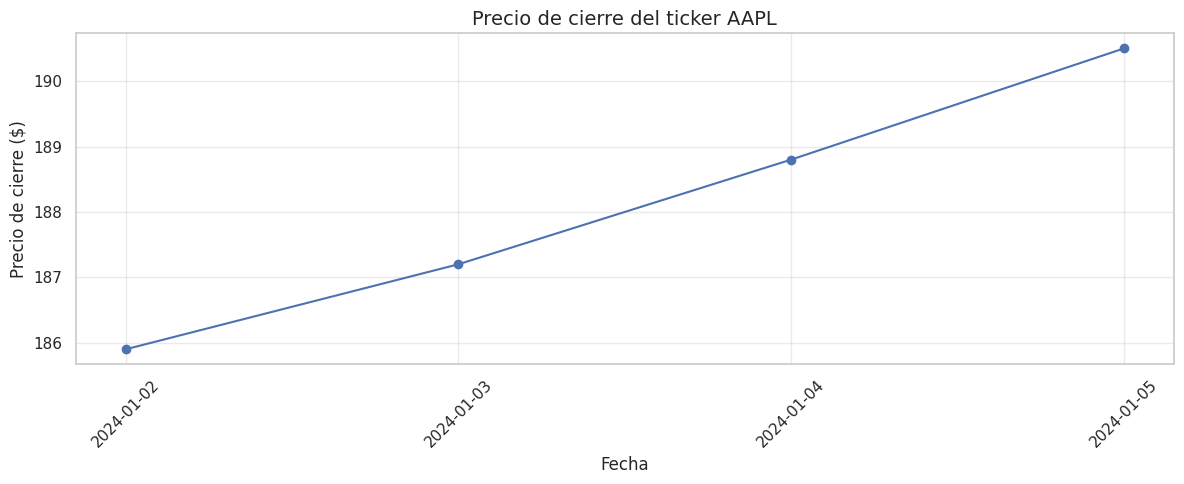

In [ ]:
plt.figure(figsize=(12, 5))


ds_acciones_grafico=ds_acciones[ds_acciones["Ticker"]=='AAPL']


plt.plot( ds_acciones_grafico["Date"] , ds_acciones_grafico["Close"] , marker="o", label=ticker)

plt.title("Precio de cierre del ticker AAPL", fontsize=14)
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

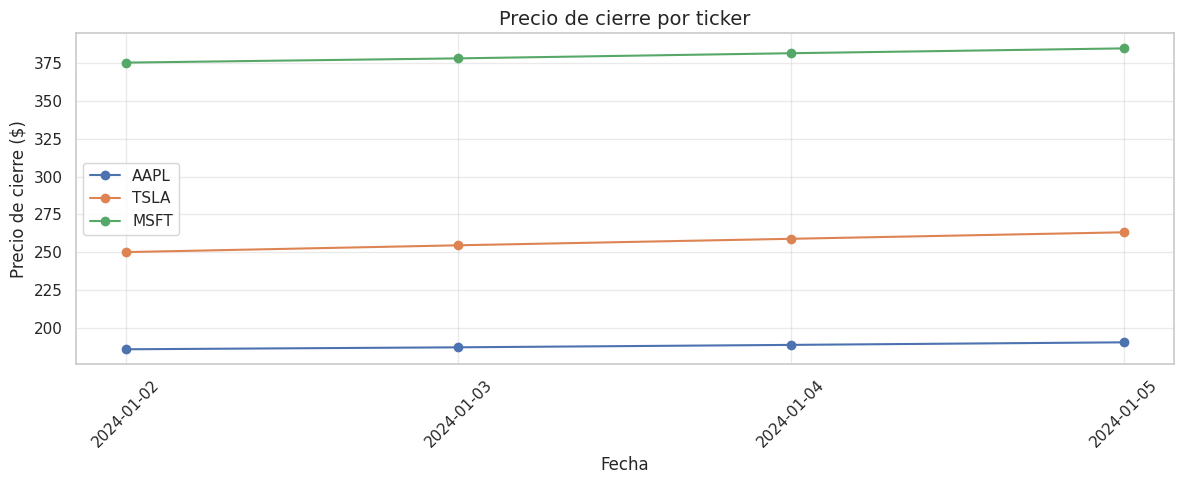

In [ ]:
plt.figure(figsize=(12, 5))

for ticker in ds_acciones["Ticker"].unique():
    df_ticker: pd.DataFrame = ds_acciones[ds_acciones["Ticker"] == ticker]

    plt.plot(df_ticker["Date"], df_ticker["Close"], marker="o", label=ticker)

plt.title("Precio de cierre por ticker", fontsize=14)
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre ($)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

#### Ingreso total por producto (barras)

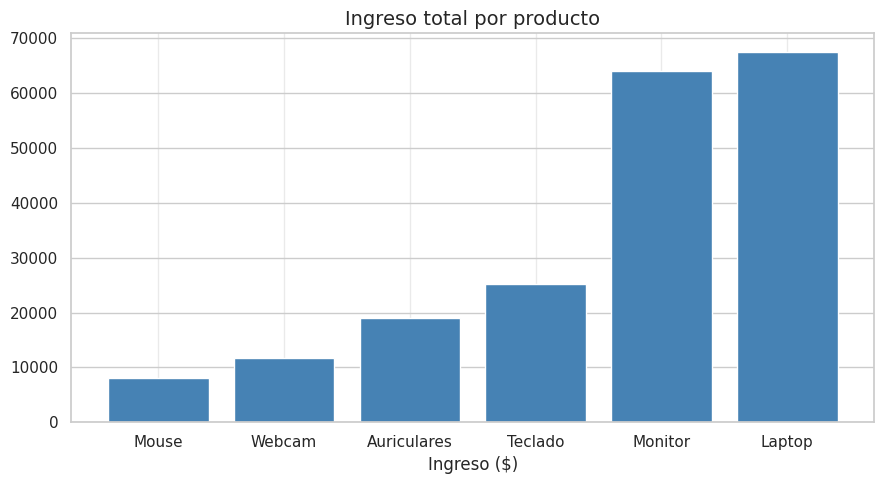

In [ ]:
df_ord: pd.DataFrame = df_productos.sort_values("ingreso_total", ascending=True)

plt.figure(figsize=(9, 5))

plt.bar( df_ord["producto"], df_ord["ingreso_total"]  , color="steelblue", edgecolor="white")

plt.title("Ingreso total por producto", fontsize=14)
plt.xlabel("Ingreso ($)")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

#### Distribución de precios de cierre (Seaborn histplot + boxplot)

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

# Histograma con KDE
sns.histplot(
    data=ds_acciones, x="Close", hue="Ticker",
    kde=True, bins=8, alpha=0.5, ax=ejes[0]
)
ejes[0].set_title("Distribución del precio de cierre")
ejes[0].set_xlabel("Precio ($)")

# Boxplot por ticker
sns.boxplot(
    data=ds_acciones, x="Ticker", y="Close",
    palette="muted", ax=ejes[1]
)
ejes[1].set_title("Rango de precios de cierre por ticker")
ejes[1].set_xlabel("Ticker")
ejes[1].set_ylabel("Precio ($)")

plt.tight_layout()
plt.show()

#### Heatmap de correlación entre variables numéricas

In [ ]:
# La matriz de correlación muestra qué tan relacionadas están las variables entre sí
# 1.0 = correlación perfecta positiva, -1.0 = perfecta negativa, 0 = sin relación
correlacion: pd.DataFrame = ds_acciones[["Open", "High", "Low", "Close", "Volume"]].corr().round(2)

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlacion,
    annot=True, fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title("Matriz de correlación", fontsize=14)
plt.tight_layout()
plt.show()

---
### **Ejemplo integrador: análisis de ventas completo**

In [ ]:
# Dataset simulado: 50 transacciones de ventas
np.random.seed(42)
n: int = 50

categorias: list[str]  = ["Tech", "Audio", "Hogar", "Oficina"]
regiones:   list[str]  = ["Norte", "Sur", "Centro"]

df_ventas: pd.DataFrame = pd.DataFrame({
    "id":         range(1, n + 1),
    "categoria":  np.random.choice(categorias, n),
    "region":     np.random.choice(regiones, n),
    "precio":     np.random.uniform(50, 2000, n).round(2),
    "cantidad":   np.random.randint(1, 10, n),
    "descuento":  np.random.choice([0.0, 0.05, 0.10, 0.15, 0.20], n),
})

# Columnas calculadas
df_ventas["subtotal"] = (df_ventas["precio"] * df_ventas["cantidad"]).round(2)
df_ventas["total"]    = (df_ventas["subtotal"] * (1 - df_ventas["descuento"])).round(2)

print("Shape:", df_ventas.shape)
print(df_ventas.head())

In [ ]:
# Estadísticas generales
print("=== RESUMEN GENERAL ===")
print(f"Total de ventas:       ${df_ventas['total'].sum():,.2f}")
print(f"Ticket promedio:       ${df_ventas['total'].mean():,.2f}")
print(f"Venta máxima:          ${df_ventas['total'].max():,.2f}")
print(f"Venta mínima:          ${df_ventas['total'].min():,.2f}")

In [ ]:
# Ventas por categoría y región
por_categoria: pd.DataFrame = df_ventas.groupby("categoria").agg(
    total_vendido   = ("total",    "sum"),
    ticket_promedio = ("total",    "mean"),
    n_transacciones = ("id",       "count")
).round(2).sort_values("total_vendido", ascending=False)

por_region: pd.DataFrame = df_ventas.groupby("region").agg(
    total_vendido   = ("total",    "sum"),
    ticket_promedio = ("total",    "mean"),
    n_transacciones = ("id",       "count")
).round(2).sort_values("total_vendido", ascending=False)

print("\n--- Por categoría ---")
print(por_categoria)
print("\n--- Por región ---")
print(por_region)

In [ ]:
# Panel de visualización
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

# Barras: total por categoría
ejes[0].bar(
    por_categoria.index,
    por_categoria["total_vendido"],
    color="steelblue", edgecolor="white"
)
ejes[0].set_title("Total vendido por categoría")
ejes[0].set_ylabel("$ vendido")
ejes[0].grid(axis="y", alpha=0.4)

# Torta: proporción por región
ejes[1].pie(
    por_region["total_vendido"],
    labels=por_region.index,
    autopct="%1.1f%%",
    colors=["steelblue", "tomato", "seagreen"],
    wedgeprops={"edgecolor": "white"}
)
ejes[1].set_title("Proporción de ventas por región")

# Histograma: distribución del total por venta
ejes[2].hist(df_ventas["total"], bins=15, color="goldenrod", edgecolor="white")
ejes[2].set_title("Distribución del monto por venta")
ejes[2].set_xlabel("Monto ($)")
ejes[2].set_ylabel("Frecuencia")
ejes[2].grid(axis="y", alpha=0.4)

plt.suptitle("Panel de análisis de ventas", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

---
### **Resumen**

| Operación | Código |
|---|---|
| Leer CSV | `pd.read_csv("archivo.csv")` |
| Crear desde dict | `pd.DataFrame(diccionario)` |
| Dimensiones | `df.shape` |
| Tipos de datos | `df.dtypes` |
| Info general | `df.info()` |
| Estadísticas | `df.describe()` |
| Primeras filas | `df.head(n)` |
| Últimas filas | `df.tail(n)` |
| Muestra aleatoria | `df.sample(n)` |
| Seleccionar columna | `df["col"]` |
| Seleccionar varias | `df[["col1", "col2"]]` |
| Acceso por posición | `df.iloc[fila, col]` |
| Acceso por etiqueta | `df.loc[fila, "col"]` |
| Filtrar filas | `df[df["col"] > valor]` |
| Filtrar con isin | `df[df["col"].isin([v1, v2])]` |
| Nueva columna | `df["nueva"] = df["a"] * df["b"]` |
| Aplicar función | `df["col"].apply(funcion)` |
| Detectar nulos | `df.isnull().sum()` |
| Eliminar nulos | `df.dropna()` |
| Rellenar nulos | `df["col"].fillna(valor)` |
| Ordenar | `df.sort_values("col", ascending=False)` |
| Frecuencias | `df["col"].value_counts()` |
| Valores únicos | `df["col"].unique()` |
| Agrupar y agregar | `df.groupby("col").agg(...)` |
| Correlación | `df.corr()` |